In [1]:
import pandas as pd

In [3]:
df = pd.read_csv("../data/raw/UCI_Credit_Card.csv")

df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [4]:
print("Размер датасета:", df.shape)
print("\nИнформация о данных:")
df.info()

Размер датасета: (30000, 25)

Информация о данных:
<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  floa

In [5]:
# Проверяем пропущенные значения
df.isnull().sum()

ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default.payment.next.month    0
dtype: int64

In [6]:
# Проверяем количество дубликатов
df.duplicated().sum()

np.int64(0)

## Проверка качества данных

In [16]:
# Распределение целевой переменной
df["default.payment.next.month"].value_counts()

default.payment.next.month
0    23364
1     6636
Name: count, dtype: int64

In [17]:
# Распределение в процентах
df["default.payment.next.month"].value_counts(normalize=True) * 100

default.payment.next.month
0    77.88
1    22.12
Name: proportion, dtype: float64

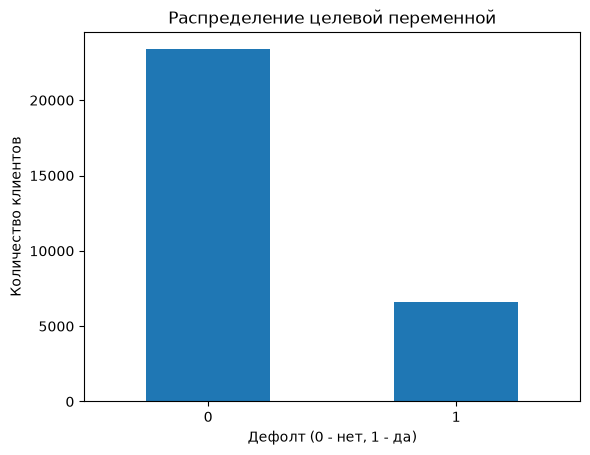

In [18]:
import matplotlib.pyplot as plt

df["default.payment.next.month"].value_counts().sort_index().plot(kind="bar")

plt.title("Распределение целевой переменной")
plt.xlabel("Дефолт (0 - нет, 1 - да)")
plt.ylabel("Количество клиентов")
plt.xticks(rotation=0)
plt.show()

Вывод: В датасете клиентов без дефолта значительно больше, чем клиентов с дефолтом (примерно 78% против 22%). Классы несбалансированы, поэтому при оценке модели важно использовать не только Accuracy, но и Precision, Recall, F1-score и ROC-AUC.

In [19]:
df.describe()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


Вывод: В датасете 30 000 записей и 25 столбцов. Пропущенных значений и полных дубликатов нет. Средний возраст клиентов составляет около 35 лет, средний кредитный лимит - около 167 тыс.

При этом обнаружены необычные значения в признаках EDUCATION и MARRIAGE. Также встречаются отрицательные суммы счетов и очень большие платежи. Эти значения нужно изучить перед обучением модели.

## Проверяем категориальные признаки

In [20]:
print("Образование:")
print(df["EDUCATION"].value_counts().sort_index())

print("\nСемейное положение:")
print(df["MARRIAGE"].value_counts().sort_index())

Образование:
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

Семейное положение:
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64


In [21]:
# Создаем копию данных
df_clean = df.copy()

# Объединяем редкие категории образования
df_clean["EDUCATION"] = df_clean["EDUCATION"].replace({0: 4, 5: 4, 6: 4})

# Объединяем редкие категории семейного положения
df_clean["MARRIAGE"] = df_clean["MARRIAGE"].replace({0: 3})

# Проверяем результат
print(df_clean["EDUCATION"].value_counts().sort_index())
print()
print(df_clean["MARRIAGE"].value_counts().sort_index())

EDUCATION
1    10585
2    14030
3     4917
4      468
Name: count, dtype: int64

MARRIAGE
1    13659
2    15964
3      377
Name: count, dtype: int64


Вывод: В признаках EDUCATION и MARRIAGE обнаружены редкие категории с неопределённым значением. Для упрощения обработки объединили их с категорией "Другое". Это позволило сохранить все наблюдения без удаления строк.

## Создаём новые признаки (Feature Engineering)

In [22]:
# Столбцы с историей платежей
pay_columns = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]

# Количество месяцев с просрочкой
df_clean["late_payments"] = (df_clean[pay_columns] > 0).sum(axis=1)

# Проверяем результат
df_clean[pay_columns + ["late_payments"]].head()

,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,late_payments
0,2,2,-1,-1,-2,-2,2
1,-1,2,0,0,0,2,2
2,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0
4,-1,0,-1,0,0,0,0


Создали новый признак late_payments - количество месяцев с просрочкой платежа за последние шесть месяцев. Он позволяет учитывать историю нарушений сроков оплаты клиента.

In [23]:
# Отношение задолженности к кредитному лимиту
df_clean["credit_utilization"] = df_clean["BILL_AMT1"] / df_clean["LIMIT_BAL"]

# Проверяем результат
df_clean[["LIMIT_BAL", "BILL_AMT1", "credit_utilization"]].head()

,LIMIT_BAL,BILL_AMT1,credit_utilization
0,20000.0,3913.0,0.195650
1,120000.0,2682.0,0.022350
2,90000.0,29239.0,0.324878
3,50000.0,46990.0,0.939800
4,50000.0,8617.0,0.172340


Создали признак credit_utilization - отношение задолженности по последнему счёту к кредитному лимиту. Он помогает оценить, насколько клиент использует предоставленный кредитный лимит.

## Изучаем распределение новых признаков

In [24]:
df_clean[["late_payments", "credit_utilization"]].describe()

,late_payments,credit_utilization
count,30000.000000,30000.000000
mean,0.834200,0.423771
std,1.554303,0.411462
min,0.000000,-0.619892
25%,0.000000,0.022032
50%,0.000000,0.313994
75%,1.000000,0.829843
max,6.000000,6.455300


In [25]:
df_clean["late_payments"].value_counts().sort_index()

late_payments
0    19931
1     4426
2     1899
3     1154
4      951
5      298
6     1341
Name: count, dtype: int64

Вывод: У большинства клиентов (66,4%) не было месяцев с просроченными платежами. При этом у части клиентов просрочки наблюдались регулярно.

Среднее отношение задолженности к кредитному лимиту составляет около 42,4%. Встречаются отрицательные значения и значения больше 100%, но пока оставим их без изменений.

Созданные признаки могут быть полезны для прогнозирования дефолта. Их влияние проверим при обучении модели.

## Проверяем связь просрочек с дефолтом

In [26]:
df_clean.groupby("late_payments")["default.payment.next.month"].mean() * 100

late_payments
0    11.710401
1    29.823769
2    38.757241
3    50.866551
4    57.308097
5    57.382550
6    70.320656
Name: default.payment.next.month, dtype: float64

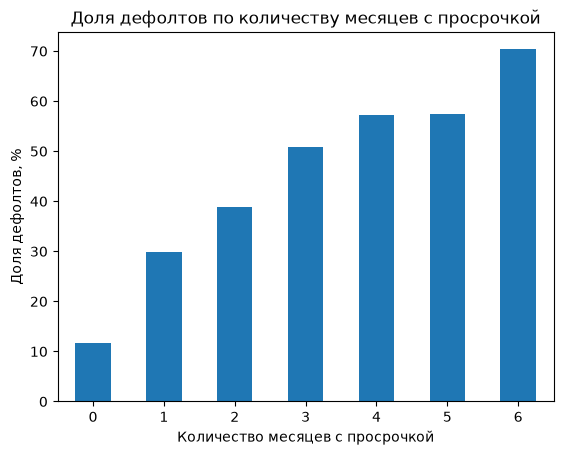

In [27]:
default_rate = df_clean.groupby("late_payments")["default.payment.next.month"].mean() * 100

default_rate.plot(kind="bar")

plt.title("Доля дефолтов по количеству месяцев с просрочкой")
plt.xlabel("Количество месяцев с просрочкой")
plt.ylabel("Доля дефолтов, %")
plt.xticks(rotation=0)
plt.show()

Вывод: Чем больше месяцев у клиента были просрочки, тем выше доля дефолтов. У клиентов без просрочек она составляет 11,7%, а у клиентов с просрочками во всех шести месяцах - 70,3%.

Это показывает, что новый признак late_payments может быть полезен при прогнозировании дефолта.

## Анализируем связь кредитной нагрузки с дефолтом

In [28]:
# Разделяем клиентов на группы по кредитной нагрузке
df_clean["utilization_group"] = pd.cut(
    df_clean["credit_utilization"],
    bins=[-float("inf"), 0, 0.25, 0.5, 0.75, 1, float("inf")],
    labels=["<=0", "0-25%", "25-50%", "50-75%", "75-100%", ">100%"]
)

# Считаем долю дефолтов в каждой группе
df_clean.groupby("utilization_group", observed=True)["default.payment.next.month"].mean() * 100

utilization_group
<=0        24.749808
0-25%      16.809441
25-50%     21.739130
50-75%     25.956971
75-100%    25.823353
>100%      30.070922
Name: default.payment.next.month, dtype: float64

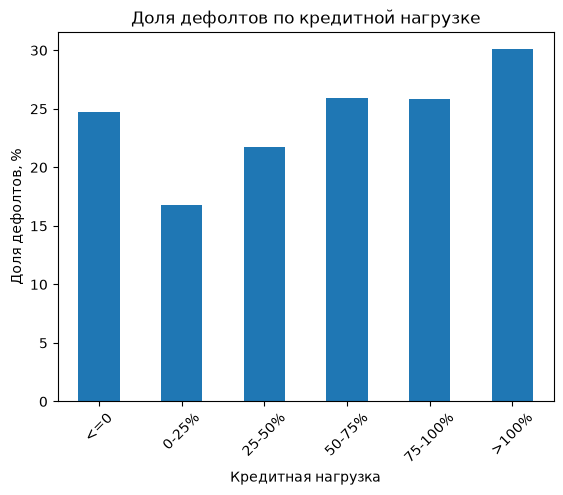

In [29]:
default_rate = df_clean.groupby("utilization_group", observed=True)["default.payment.next.month"].mean() * 100

default_rate.plot(kind="bar")

plt.title("Доля дефолтов по кредитной нагрузке")
plt.xlabel("Кредитная нагрузка")
plt.ylabel("Доля дефолтов, %")
plt.xticks(rotation=45)
plt.show()

Вывод: В целом при увеличении кредитной нагрузки доля дефолтов растёт. Самая низкая доля наблюдается при нагрузке до 25%, а самая высокая - при превышении кредитного лимита.

При этом зависимость не совсем равномерная. Признак credit_utilization оставим для дальнейшего обучения модели и проверим его полезность.

## Результаты базовой модели Logistic Regression

Первая модель показала ROC-AUC = 0.7076, Precision = 0.6868, Recall = 0.2396 и F1-score = 0.3553.

Модель лучше случайного классификатора различает клиентов с дефолтом и без него, но обнаруживает только около 24% реальных дефолтов. Поэтому в дальнейшем нужно попробовать улучшить Recall и F1-score.

## Сравнение моделей

После добавления признаков late_payments и credit_utilization качество логистической регрессии улучшилось. ROC-AUC вырос с 0.7076 до 0.7393, а F1-score с 0.3553 до 0.4040.

Recall тоже увеличился, хотя Precision немного снизился. Новые признаки оказались полезными для модели, поэтому оставим их для дальнейшего обучения.##

## Результаты обработки категориальных признаков

После применения ColumnTransformer ROC-AUC немного вырос и составил 0.7413. При этом F1-score снизился до 0.3985.

Новый вариант лучше разделяет классы по ROC-AUC, но по F1-score немного уступает предыдущему. Дальше попробуем подобрать гиперпараметры модели.

## Подбор гиперпараметров

С помощью GridSearchCV проверили четыре значения параметра C. Лучшим оказалось C = 1, средний ROC-AUC на кросс-валидации составил 0.7566.

После подбора качество на тестовой выборке не изменилось: ROC-AUC = 0.7413, F1-score = 0.3985. Это связано с тем, что выбранное значение C уже использовалось в модели по умолчанию.